<a href="https://colab.research.google.com/github/ShamaimI/ANN-DL/blob/main/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task: Implement ADALINE from scratch to learn the OR gate using the bipolar coding convention (inputs and targets −1/+1). Do not use a neural-network library for the weight updates.
Requirement	What to submit	Marks
Dataset and coding	Truth table for OR using bipolar values	5
Algorithm	Correct net input, error, and delta-rule updates	15
Training evidence	MSE per epoch and a learning curve	10
Evaluation	Final weights/bias and predictions for all four inputs	10
Discussion	Explain convergence and compare AND/OR separability with XOR	10
Total		50




Weights: [0.47058824 0.44117647]
Bias: 0.5000000000000001

Input | Linear output | Predicted | Target
[-1 -1] -0.412 -1 -1
[-1  1] 0.471 1 1
[ 1 -1] 0.529 1 1
[1 1] 1.412 1 1


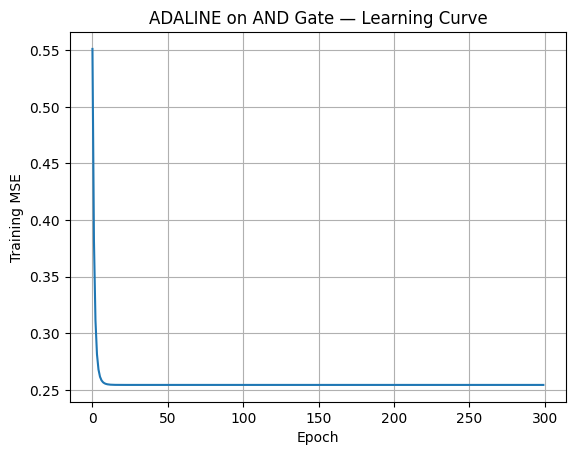

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# xor gate dataset
X = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]], dtype=float)
y = np.array([-1, 1, 1, 1], dtype=float)

# Reproducible initialization
rng = np.random.default_rng(7)
w = rng.normal(0, 0.1, size=2)
b = 0.0
learning_rate = 0.1
epochs = 300

loss_history = []

for epoch in range(epochs):
    # Online ADALINE updates
    for xi, target in zip(X, y):
        output = np.dot(xi, w) + b       # linear output (not thresholded)
        error = target - output
        w += learning_rate * error * xi
        b += learning_rate * error

    # MSE after the epoch
    outputs = X @ w + b
    mse = np.mean((y - outputs) ** 2)
    loss_history.append(mse)

print("Weights:", w)
print("Bias:", b)
print("\nInput | Linear output | Predicted | Target")
for xi, target, output in zip(X, y, X @ w + b):
    predicted = 1 if output >= 0.0 else -1
    print(xi.astype(int), f"{output:.3f}", predicted, int(target))

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("ADALINE on AND Gate — Learning Curve")
plt.grid(True)
plt.show()


Graded Task 2 — MADALINE
Task: Extend the MADALINE-style Iris experiment by changing the hidden-unit count and comparing two settings (for example, 2 and 4 hidden ADALINE units). Keep the same stratified split and training-only scaling. Clearly identify the learning-rule variant used.
Requirement	What to submit	Marks
Data preparation	Explain binary target encoding and split; prevent leakage	10
Model implementation	Architecture and documented update rule	15
Learning curves	Training and validation loss curves for both settings	10
Evaluation	Validation and test accuracy with confusion matrix	10
Discussion	Compare hidden-unit settings and explain limitations	5
Total		50



 TRAINING MADALINE WITH 2 HIDDEN UNITS
Train Accuracy:      1.000
Validation Accuracy: 1.000
Test Accuracy:       1.000

Validation Confusion Matrix:
[[10  0]
 [ 0 20]]
Test Confusion Matrix:
[[10  0]
 [ 0 20]]
 TRAINING MADALINE WITH 4 HIDDEN UNITS
Train Accuracy:      1.000
Validation Accuracy: 1.000
Test Accuracy:       1.000

Validation Confusion Matrix:
[[10  0]
 [ 0 20]]
Test Confusion Matrix:
[[10  0]
 [ 0 20]]


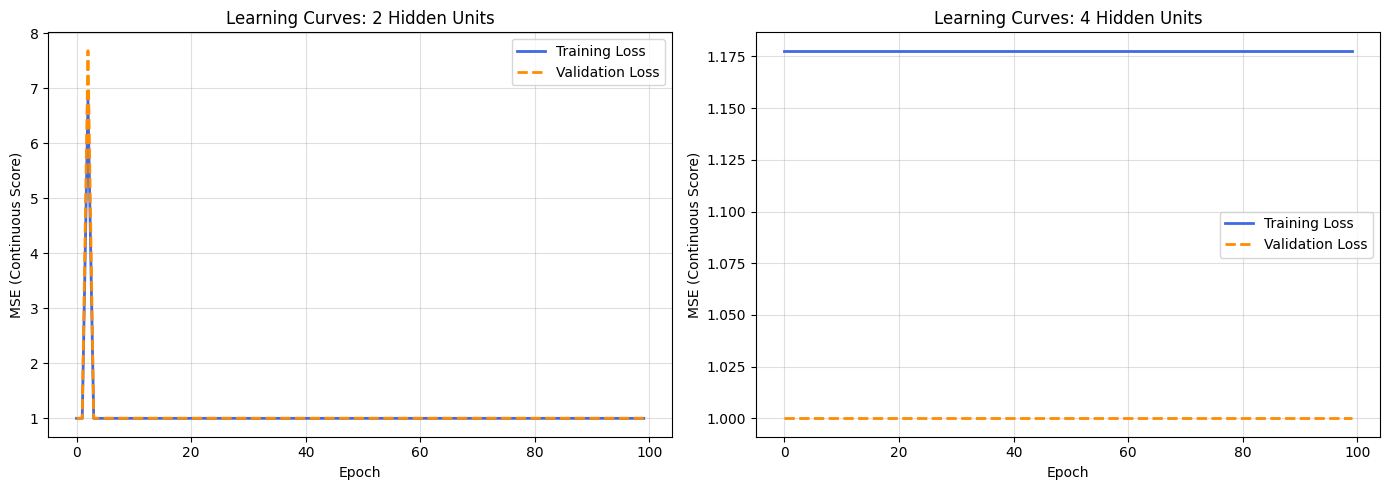

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# 1) Load Iris dataset: setosa = -1.0, versicolor/virginica = +1.0
iris = load_iris()
X = iris.data.astype(float)
y = np.where(iris.target == 0, -1.0, 1.0)

# 2) Split data: 60% train, 20% validation, 20% test (Stratified to maintain class balance)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Fit scaler ONLY on training data to strictly prevent data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

class SimpleMadaline:
    """
    MADALINE network supporting configurable hidden ADALINE units
    using the Madaline Rule II (MRII) adaptation mechanism.
    """
    def __init__(self, n_features, n_hidden=2, lr=0.02, seed=12):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.15, (n_features, n_hidden))
        self.bh = np.zeros(n_hidden)
        self.v = np.ones(n_hidden)  # Hidden-to-output matrix configurations
        self.bo = 0.0
        self.lr = lr

    def forward(self, X_input):
        hidden_net = X_input @ self.W + self.bh
        hidden = np.where(hidden_net >= 0, 1.0, -1.0)
        # Continuous score profile for MSE observation
        score = hidden @ self.v + self.bo
        return hidden_net, hidden, score

    def predict(self, X_input):
        _, _, score = self.forward(X_input)
        return np.where(score >= 0, 1.0, -1.0)

    def fit(self, X_data, y_data, X_v, y_v, epochs=100):
        train_losses, val_losses = [], []
        for epoch in range(epochs):
            for xi, target in zip(X_data, y_data):
                nets, hidden, score = self.forward(xi.reshape(1, -1))
                nets, hidden, score = nets[0], hidden[0], float(score[0])

                pred = 1.0 if score >= 0 else -1.0
                if pred != target:
                    # MRII strategy: Adjust the hidden unit closest to its decision threshold
                    j = int(np.argmin(np.abs(nets)))
                    desired = 0.5 * target
                    error = desired - nets[j]

                    # Weight updates performed manually via NumPy
                    self.W[:, j] += self.lr * error * xi
                    self.bh[j] += self.lr * error

                    # Maintain output combination configuration matrix updates
                    self.v[j] = target
                    self.bo += self.lr * (target - score) * 0.1

            # Monitor Continuous MSE loss tracking metrics
            tr_score = self.forward(X_data)[2]
            va_score = self.forward(X_v)[2]
            train_losses.append(np.mean((y_data - tr_score) ** 2))
            val_losses.append(np.mean((y_v - va_score) ** 2))

        return train_losses, val_losses

# --- RUN CONFIGURATION COMPARISONS ---
hidden_settings = [2, 4]
results = {}

plt.figure(figsize=(14, 5))

for idx, n_units in enumerate(hidden_settings, 1):
    print(f" TRAINING MADALINE WITH {n_units} HIDDEN UNITS")

    model = SimpleMadaline(n_features=X_train.shape[1], n_hidden=n_units, lr=0.02, seed=12)
    train_loss, val_loss = model.fit(X_train, y_train, X_val, y_val, epochs=100)

    # Calculate performance metrics
    train_acc = np.mean(model.predict(X_train) == y_train)
    val_acc = np.mean(model.predict(X_val) == y_val)
    test_acc = np.mean(model.predict(X_test) == y_test)

    print(f"Train Accuracy:      {train_acc:.3f}")
    print(f"Validation Accuracy: {val_acc:.3f}")
    print(f"Test Accuracy:       {test_acc:.3f}")

    # Generate Confusion Matrices for validation and testing spaces
    val_preds = model.predict(X_val)
    test_preds = model.predict(X_test)

    print("\nValidation Confusion Matrix:")
    print(confusion_matrix(y_val, val_preds, labels=[-1.0, 1.0]))
    print("Test Confusion Matrix:")
    print(confusion_matrix(y_test, test_preds, labels=[-1.0, 1.0]))

    # Plot side-by-side comparative curves
    plt.subplot(1, 2, idx)
    plt.plot(train_loss, label="Training Loss", color="royalblue", lw=2)
    plt.plot(val_loss, label="Validation Loss", color="darkorange", linestyle="--", lw=2)
    plt.xlabel("Epoch")
    plt.ylabel("MSE (Continuous Score)")
    plt.title(f"Learning Curves: {n_units} Hidden Units")
    plt.legend()
    plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()
